In [1]:
import os
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'

import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_anim

from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions

In [2]:
class ShallowWaterEquationsIntegrator:
    def __init__(self, *, h0, options = None):
      options = options or Options(nonoscillatory=True, infinite_gauge=True)
      X, Y, grid = 0, 1, h0.shape
      stepper = Stepper(options=options, grid=grid)
      boundary_cond = [boundary_conditions.Constant(value=0)] * len(grid)
      advectees = {
          "h": ScalarField(h0, options.n_halo, boundary_cond),
          "uh": ScalarField(np.zeros(grid), options.n_halo, boundary_cond),
          "vh": ScalarField(np.zeros(grid), options.n_halo, boundary_cond),
      }
      self.advector = VectorField((
              np.zeros((grid[X] + 1, grid[Y])),
              np.zeros((grid[X], grid[Y] + 1))
          ), options.n_halo, boundary_cond
      )
      self.solvers = { k: Solver(stepper, v, self.advector) for k, v in advectees.items() }

    def __getitem__(self, key):
        return self.solvers[key].advectee.get()

    def _apply_half_rhs(self, *, key, dt, axis, grid_step):
      self[key][:] -= dt / 2 * self['h'] * np.gradient(self['h'], grid_step[axis], axis=axis)

    def _update_courant_numbers(self, *, axis, key, mask, dt, grid_step):
      velocity = np.where(mask, np.nan, 0)
      momentum = self[key]
      np.divide(momentum, self['h'], where=mask, out=velocity)

      # using slices to ensure views (over copies)
      all = slice(None, None)
      all_but_last = slice(None, -1)
      all_but_first_and_last = slice(1, -1)

      velocity_at_cell_boundaries = velocity[(
          (all_but_last, all),
          (all, all_but_last),
      )[axis]] + np.diff(velocity, axis=axis) / 2
      courant_number = self.advector.get_component(axis)[(
          (all_but_first_and_last, all),
          (all, all_but_first_and_last)
      )[axis]]
      courant_number[:] = velocity_at_cell_boundaries * dt / grid_step[axis]
      assert np.amax(np.abs(courant_number)) <= 1

    def __call__(self, *, nt, grid_step, dt, outfreq, eps=1e-7):
        output = {k: [] for k in self.solvers.keys()}
        for it in range(nt + 1):
            if it != 0:
                mask = self['h'] > eps
                for axis, key in enumerate(("uh", "vh")):
                    self._update_courant_numbers(axis=axis, key=key, mask=mask, dt=dt, grid_step=grid_step)
                self.solvers["h"].advance(n_steps=1)
                for axis, key in enumerate(("uh", "vh")):
                    self._apply_half_rhs(key=key, axis=axis, dt=dt, grid_step=grid_step)
                    self.solvers[key].advance(n_steps=1)
                    self._apply_half_rhs(key=key, axis=axis, dt=dt, grid_step=grid_step)
            if it % outfreq == 0:
                for key in self.solvers.keys():
                    output[key].append(self[key].copy())
        return output


In [3]:
h0 = np.zeros((50, 40))
h0[20:30, 15:25] = 0.05
swei = ShallowWaterEquationsIntegrator(h0=h0)
output = swei(nt=250, grid_step=(0.05, 0.05), dt=0.01, outfreq=10)


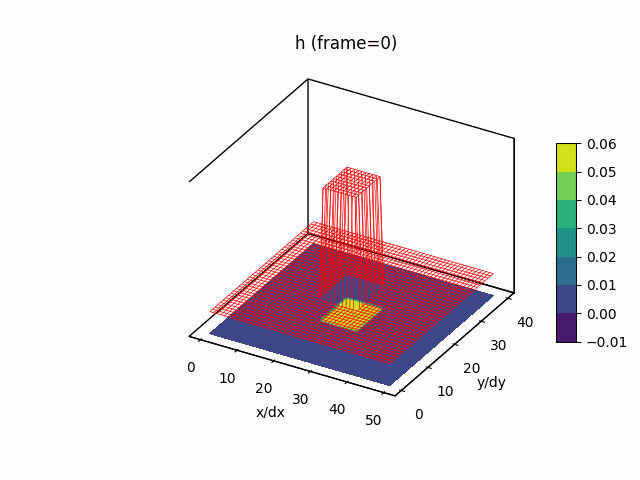

Button(description='tmpx2uu5v3u.gif', style=ButtonStyle())

In [4]:
def plot(frame, zlim=(-.01, .06)):
    psi = output['h'][frame]
    xi, yi = np.indices(psi.shape)
    fig, ax = pyplot.subplots(subplot_kw={"projection": "3d"})
    pyplot.gca().plot_wireframe(
        xi+.5, yi+.5,
        psi, color='red', linewidth=.5
    )
    ax.set_zlim(zlim)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor('black')
        axis.pane.set_alpha(1)
    ax.grid(False)
    ax.set_zticks([])
    for axis in ('x', 'y'): getattr(ax, f'set_{axis}label')(f"{axis}/d{axis}")
    ax.set_proj_type('ortho')
    cnt = ax.contourf(xi+.5, yi+.5, psi, zdir='z', offset=zlim[0], levels=np.linspace(*zlim, 8))
    cbar = pyplot.colorbar(cnt, ax=ax, pad=.05, aspect=10, fraction=.04)
    ax.set_title(f"h ({frame=})")
    return fig
show_anim(plot, range(len(output['h'])))